# Business & revenue (measured)

**Block II — measured.** This notebook describes the **real** feeds: `orders` and `bookings_legs` (the islands) and the clickstream `events` / `sessions`. It is the "measured" half of the lab.

> **Island caveat — read first.** Every number here is **measured**, but two of the four tables are **islands**. `orders` and `bookings_legs` carry **no `user_id` and no foreign key** — not to each other, not to the clickstream. And `orders` (**Nov 2023 – Jan 2024**) does **not overlap in time** with the clickstream (**May 2023**). **No unified end-to-end funnel is possible**, and the two blocks are never fused (see `docs/adr/0001-modeled-vs-measured.md`).

Evidence class for this entire notebook: **measured**.

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import Image, display, Markdown

PROJECT_ROOT = Path("..").resolve()
REPORTS = PROJECT_ROOT / "reports"
FIGURES = REPORTS / "figures"

business = json.loads((REPORTS / "business.json").read_text(encoding="utf-8"))
print("business.json sections:", list(business))
print("evidence class: MEASURED (real feeds; orders/bookings_legs are islands)")

business.json sections: ['orders', 'routes', 'clickstream_ab', 'modeled']
evidence class: MEASURED (real feeds; orders/bookings_legs are islands)


## 2. Clickstream A/B — activity-level, a volume metric

The clickstream carries `ab_group` (A/B) per user, so the split can be checked — but `events` has **no event taxonomy** (only `user_id`, `ab_group`, `ts`, `pdate`). With no named funnel steps there is **no conversion metric**; the honest primary metric is **volume** (events / sessions per user), **not** funnel conversion. The arms are balanced (SRM p-value = 1.0) and per-user volume is near-identical across arms.

,source,ab_group,users,srm_chi2,srm_p_value
0,events,A,2500,0.0,1.0
1,events,B,2500,0.0,1.0
2,sessions,A,2500,0.0,1.0
3,sessions,B,2500,0.0,1.0


,metric,ab_group,mean,median
0,events_per_user,A,8.8512,6.0
1,events_per_user,B,8.9760,6.0
2,sessions_per_user,A,2.0164,2.0
3,sessions_per_user,B,2.0248,2.0


SRM p-value: 1.0


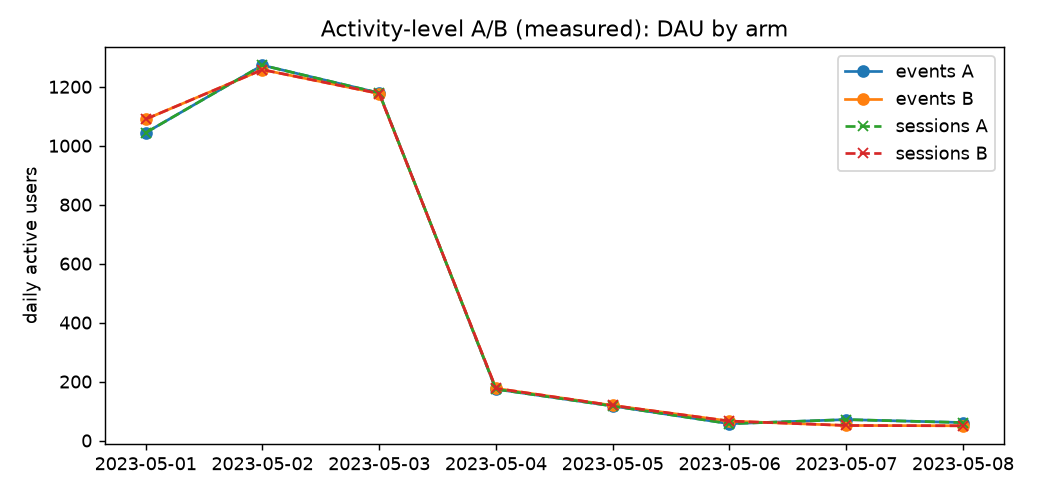

In [2]:
bal = pd.DataFrame(business["clickstream_ab"]["balance"])
per_user = pd.DataFrame(business["clickstream_ab"]["per_user"])
display(bal)
display(per_user.round(4))

print("SRM p-value:", bal["srm_p_value"].iloc[0])

display(Image(filename=str(FIGURES / "ab_activity.png")))

*Figure caption:* daily active users by arm, from `events` and `sessions`. This is a **volume-level** view. Because `events` has no event taxonomy, it can only say whether activity volume differs between arms — it is **not** funnel conversion.

## 3. Orders & ancillary — service mix, refunds, booking depth, price

`orders_metrics` (`src/business.py`) summarises the orders island. Most orders carry **no service label** (79.6%); among labelled ones, `notification` and `changes` dominate. The refund rate is **2.68%** (240 of 8,966 rows). Ancillary economics are thin in coverage, not in level: `service_profit` is labelled on only **20.4%** of rows (1,830), and among those the median is **399.2 ₽** — the other 79.6% are unlabelled, not zeros. Any profit read over the full table is therefore a statement about labelled services only.

One structural trap: `orders` is **order x service**, not one row per order — 8,966 rows, 8,803 unique `order_id`, i.e. 163 duplicated `order_id` rows. Count orders by `order_id`, never by row.

,service,count,share
0,(none),7136,0.7959
1,notification,1100,0.1227
2,changes,476,0.0531
3,refund,240,0.0268
4,support,14,0.0016


refund rate: 2.68%


,order_platform,count,share
0,desktop,3507,0.3911
1,ios,2585,0.2883
2,android,1383,0.1542
3,android_web,531,0.0592
4,ios_web,510,0.0569
5,(none),433,0.0483
6,other,17,0.0019


price medians (order / service / service_profit): [{'order_price_50%': 15363.055972499998, 'service_price_50%': 499.0, 'service_profit_50%': 399.2}]
service_profit median=399.2 (~0); service labelled on 20% of orders


**Booking-depth distribution (binned)**

,bin_left,bin_right,count
0,0.07,33.06,8181
1,33.06,66.05,520
2,66.05,99.05,150
3,99.05,132.04,52
4,132.04,165.03,24
5,165.03,198.03,13
6,198.03,231.02,8
7,231.02,264.01,3
8,264.01,297.01,4
9,297.01,330.00,11


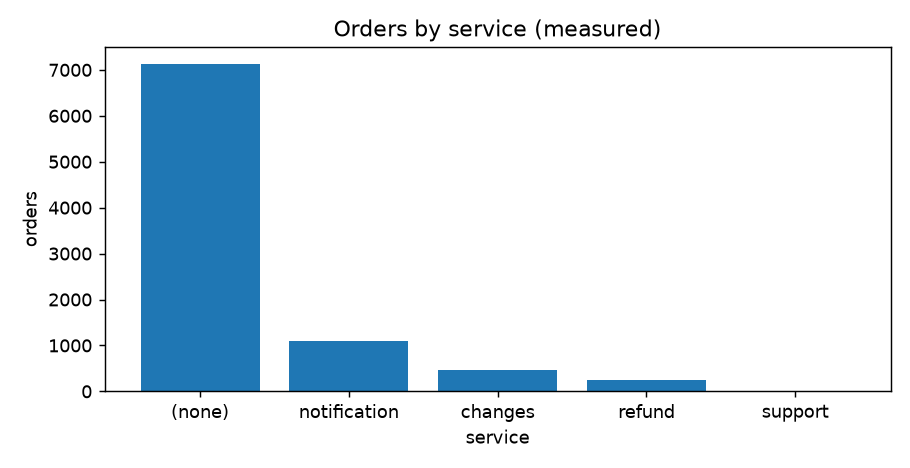

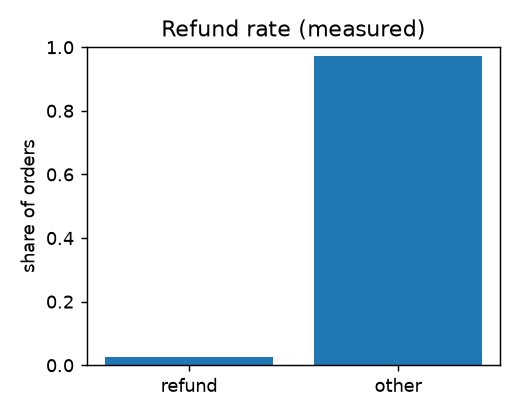

In [3]:
service_mix = pd.DataFrame(business["orders"]["service_mix"])
platform_mix = pd.DataFrame(business["orders"]["platform_mix"])
booking_depth = pd.DataFrame(business["orders"]["booking_depth"])
price_stats = pd.DataFrame(business["orders"]["price_stats"])

display(service_mix[["service", "count", "share"]].round(4))

refund_share = service_mix.loc[service_mix["service"] == "refund", "share"].iloc[0]
print(f"refund rate: {refund_share:.2%}")

display(platform_mix[["order_platform", "count", "share"]].round(4))

print("price medians (order / service / service_profit):",
      price_stats[["order_price_50%", "service_price_50%", "service_profit_50%"]].to_dict("records"))
print(price_stats["note"].iloc[0])

display(Markdown("**Booking-depth distribution (binned)**"))
display(booking_depth.round(2))

display(Image(filename=str(FIGURES / "orders_mix.png")))
display(Image(filename=str(FIGURES / "refund_rate.png")))

## 4. Supply & routes — airlines, LED concentration, seasonality

`routes_metrics` (`src/business.py`) summarises the bookings-legs island. Supply is concentrated: **DP 29.8%**, then SU 15.3% and FV 14.6%. Routes are even more concentrated — **LED (St. Petersburg) is the destination of 95.8% of legs**, and SVO/VKO/DME -> LED alone are 95.1% of all legs. Connections are rare (1.1%) and baggage is carried on 14.6% of legs. Seasonality peaks in summer: May–Aug carry 14.7–16.4% of legs each against 7.9–10.7% in Jan–Apr.

,airline,count,share
0,DP,40776,0.2975
1,SU,20996,0.1532
2,FV,19994,0.1459
3,5N,15680,0.1144
4,UT,8108,0.0592
5,U6,7991,0.0583
6,N4,7859,0.0573
7,S7,7491,0.0547


,origin,destination,count,share
0,SVO,LED,59354,0.4331
1,VKO,LED,52926,0.3862
2,DME,LED,18996,0.1386
3,SVO,HKT,2694,0.0197
4,AUH,HKT,468,0.0034


connection share: 0.011   baggage share: 0.146


**Seasonality — legs by booking month (1-8)**

,booking_month,legs,share
0,1,13264,0.0968
1,2,10833,0.0790
2,3,12992,0.0948
3,4,14596,0.1065
4,5,20206,0.1474
5,6,22458,0.1639
6,7,21990,0.1605
7,8,20707,0.1511


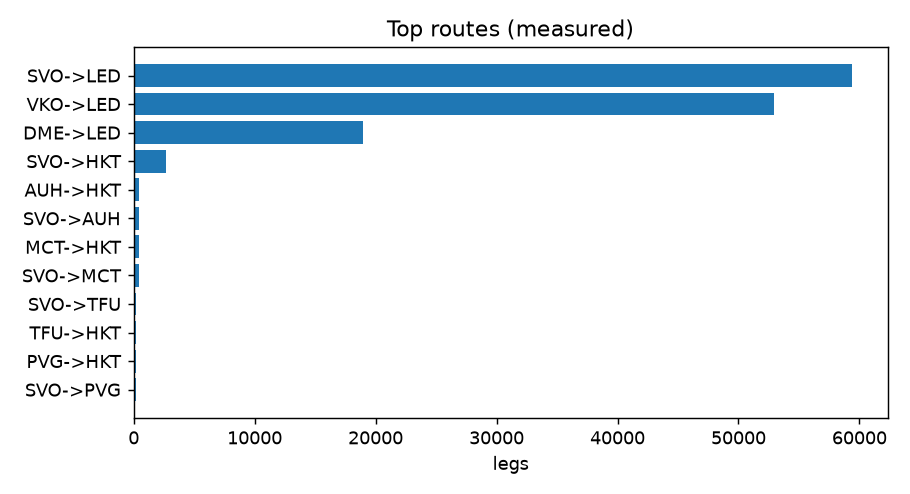

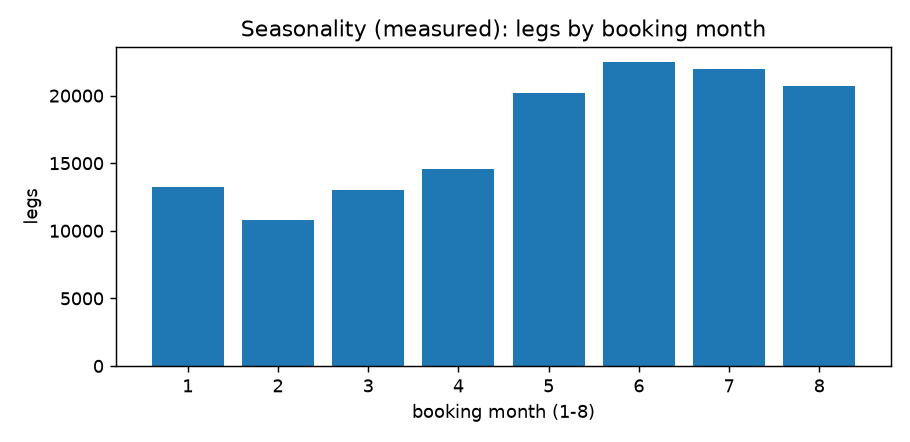

In [4]:
airlines = pd.DataFrame(business["routes"]["airlines"])
routes = pd.DataFrame(business["routes"]["routes"])
monthly = pd.DataFrame(business["routes"]["monthly"])

display(airlines.head(8)[["airline", "count", "share"]].round(4))
display(routes.head(5)[["origin", "destination", "count", "share"]].round(4))

print("connection share: %.3f   baggage share: %.3f" % (
    routes["connection_share"].iloc[0], routes["baggage_share"].iloc[0]))

display(Markdown("**Seasonality — legs by booking month (1-8)**"))
display(monthly.round(4))

display(Image(filename=str(FIGURES / "routes.png")))
display(Image(filename=str(FIGURES / "seasonality.png")))

## 5. Business conclusion

**Measured — islands, no fused funnel.** What an analyst would act on:

- **Route concentration is the top risk.** 95.8% of legs land at LED, and SVO/VKO/DME -> LED is 95.1% of volume. A supply or pricing shock on the Moscow -> St. Petersburg corridor dominates the whole feed; route diversification is the strategic lever.
- **Refunds are small but a real lever.** 2.68% of rows are refunds; combined with thin ancillary coverage (20.4% labelled), refund *drivers* cannot be modelled until services are better tagged. Refund rate also cannot be an experiment guardrail: there is no join between `orders` and the ranking.
- **Ancillary margin is a coverage problem, not a zero.** Among the 20.4% of rows that carry `service_profit`, the median is 399.2 ₽; the rest are unlabelled. Reporting 0 for the full table would be a data-quality error, not a finding.
- **The A/B is a volume check, not a conversion verdict.** With no event taxonomy, the clickstream can only report whether activity **volume** differs between arms — never whether a funnel converted.

Caveat restated: all of this is **measured**, but `orders` and `bookings_legs` are islands with no join key and no time overlap with the clickstream — **no unified funnel**, and the two blocks are never fused (`docs/adr/0001-modeled-vs-measured.md`).